In [ ]:
from google.colab import drive
drive.mount('/content/drive')

!mkdir -p /content/drive/MyDrive/PhoBERT_UIT_VSFC/checkpoints
!mkdir -p /content/drive/MyDrive/PhoBERT_UIT_VSFC/wandb_logs

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
!git clone -b feat/phobert-analysis https://github.com/Perfect-Kopiko/Vietnamese-Sentiment-Analysis.git
%cd Vietnamese-Sentiment-Analysis
!pip install -q -r requirements.txt
!python data/download_data.py

Cloning into 'Vietnamese-Sentiment-Analysis'...
remote: Enumerating objects: 122, done.
remote: Counting objects: 100% (122/122), done.
remote: Compressing objects: 100% (88/88), done.
remote: Total 122 (delta 21), reused 116 (delta 15), pack-reused 0 (from 0)
Receiving objects: 100% (122/122), 58.38 KiB | 14.60 MiB/s, done.
Resolving deltas: 100% (21/21), done.
/content/Vietnamese-Sentiment-Analysis/Vietnamese-Sentiment-Analysis
[*] Đang tải bộ dữ liệu 'uit-nlp/vietnamese_students_feedback' từ HuggingFace...
[+] Đã lưu 'train' vào: /content/Vietnamese-Sentiment-Analysis/Vietnamese-Sentiment-Analysis/data/raw/train.csv
--- Thống kê split: TRAIN ---
Tổng số mẫu: 11,426
  Nhãn 0 (Negative): 5,325 (46.60%)
  Nhãn 1 (Neutral): 458 (4.01%)
  Nhãn 2 (Positive): 5,643 (49.39%)

[+] Đã lưu 'validation' vào: /content/Vietnamese-Sentiment-Analysis/Vietnamese-Sentiment-Analysis/data/raw/validation.csv
--- Thống kê split: VALIDATION ---
Tổng số mẫu: 1,583
  Nhãn 0 (Negative): 705 (44.54%)
  Nhãn 1

In [ ]:
!python -c "import torch; print('GPU:', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'None')"
!wandb offline

GPU: Tesla T4
wandb: Updated settings file /content/Vietnamese-Sentiment-Analysis/Vietnamese-Sentiment-Analysis/wandb/settings
W&B offline. Running your script from this directory will only write metadata locally. Use `wandb disabled` to completely turn off W&B.


In [ ]:
!bash scripts/run_ablation.sh

1/4: FULL PIPELINE (Baseline chuẩn)
Thiết bị chạy: cuda
Tiền xử lý: use_segment=True, normalize_noise=True
config.json: 100% 678/678 [00:00<00:00, 3.75MB/s]
vocab.txt: 100% 895k/895k [00:00<00:00, 51.2MB/s]
bpe.codes: 100% 1.14M/1.14M [00:00<00:00, 99.4MB/s]
tokenizer.json: 100% 3.13M/3.13M [00:00<00:00, 152MB/s]

pytorch_model.bin: downloading bytes:  66% 359M/540M [00:02<00:00, 216MB/s, 29.4MB/s  ]
pytorch_model.bin: downloading bytes:  72% 389M/540M [00:03<00:00, 187MB/s, 33.0MB/s  ]
pytorch_model.bin: downloading bytes:  87% 471M/540M [00:03<00:00, 199MB/s, 38.2MB/s  ]
pytorch_model.bin: downloading bytes:  93% 503M/540M [00:03<00:00, 183MB/s, 40.7MB/s  ]
pytorch_model.bin: reconstructing file:  74% 402M/540M [00:03<00:01, 132MB/s, 29.8MB/s  ]
pytorch_model.bin: downloading bytes: 100% 514M/514M [00:04<00:00, 119MB/s, 42.4MB/s  ]
pytorch_model.bin: reconstructing file: 100% 540M/540M [00:04<00:00, 125MB/s, 46.8MB/s  ]
Loading weights: 100% 197/197 [00:00<00:00, 24631.19it/s]
[trans

In [ ]:
!cp -r checkpoints/* /content/drive/MyDrive/PhoBERT_UIT_VSFC/checkpoints/
!cp -r wandb /content/drive/MyDrive/PhoBERT_UIT_VSFC/wandb_logs/
!ls -la /content/drive/MyDrive/PhoBERT_UIT_VSFC/checkpoints/

total 25
drwx------ 6 root root 4096 Nov 24 01:09 .
drwx------ 4 root root 4096 Nov 23 23:26 ..
drwx------ 2 root root 4096 Nov 24 01:09 ablation_no_norm
drwx------ 2 root root 4096 Nov 24 01:09 ablation_no_segment
drwx------ 2 root root 4096 Nov 24 01:09 ablation_no_weights
-rw------- 1 root root  477 Nov 24 01:09 ablation_summary.csv
drwx------ 2 root root 4096 Nov 24 01:09 best_phobert
-rw------- 1 root root   56 Nov 24 01:09 README.md


In [ ]:
!git pull origin feat/phobert-analysis
!python src/evaluation/sarcasm_analyzer.py
!cp -r results /content/drive/MyDrive/PhoBERT_UIT_VSFC/

remote: Enumerating objects: 15, done.
remote: Counting objects: 100% (15/15), done.
remote: Compressing objects: 100% (5/5), done.
remote: Total 8 (delta 3), reused 8 (delta 3), pack-reused 0 (from 0)
Unpacking objects: 100% (8/8), 6.67 KiB | 1.33 MiB/s, done.
From https://github.com/Perfect-Kopiko/Vietnamese-Sentiment-Analysis
 * branch            feat/phobert-analysis -> FETCH_HEAD
   d4dece4..dc375c3  feat/phobert-analysis -> origin/feat/phobert-analysis
Updating d4dece4..dc375c3
Fast-forward
 data/resources/sarcasm_test.csv    |  70 +++++++++++++++++
 src/evaluation/sarcasm_analyzer.py | 150 +++++++++++++++++++++++++++++++++++++
 2 files changed, 220 insertions(+)
Đã tải 70 câu từ data/resources/sarcasm_test.csv

Đang đánh giá PhoBERT...
Loading weights: 100% 197/197 [00:00<00:00, 7760.81it/s]
[transformers] RobertaModel LOAD REPORT from: vinai/phobert-base-v2
Key                       | Status     | 
--------------------------+------------+-
lm_head.dense.bias        | UNEXPECTED

In [ ]:
import os
import sys
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import seaborn as sns
from transformers import AutoTokenizer
from sklearn.metrics import confusion_matrix, classification_report

# Thêm thư mục hiện tại (gốc dự án) vào sys.path
project_root = os.path.abspath(".")
if project_root not in sys.path:
    sys.path.insert(0, project_root)

from src.preprocessing import preprocess_pipeline
from src.models.phobert_classifier import PhoBERTClassifier

os.makedirs("results/figures", exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
CHECKPOINT_DIR = "checkpoints/best_phobert"
LABEL_NAMES = ["Negative", "Neutral", "Positive"]

tokenizer = AutoTokenizer.from_pretrained(CHECKPOINT_DIR)
model = PhoBERTClassifier(pretrained_name="vinai/phobert-base-v2", num_classes=3)
model.load_state_dict(torch.load(os.path.join(CHECKPOINT_DIR, "model.pt"), map_location=DEVICE))
model.to(DEVICE)
model.eval()

print(f"Đã nạp model từ {CHECKPOINT_DIR} trên thiết bị: {DEVICE}")

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaModel LOAD REPORT from: vinai/phobert-base-v2
Key                       | Status     | 
--------------------------+------------+-
lm_head.dense.weight      | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
pooler.dense.weight       | MISSING    | 
pooler.dense.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Đã nạp model từ checkpoints/best_phobert trên thiết bị: cuda


In [ ]:
test_df = pd.read_csv("data/raw/test.csv")
test_df["clean_text"] = test_df["text"].apply(
    lambda x: preprocess_pipeline(x, use_segment=True, normalize_noise=True)
)

preds, probs_all = [], []
batch_size = 32

with torch.no_grad():
    for i in range(0, len(test_df), batch_size):
        batch_texts = test_df["clean_text"].iloc[i:i+batch_size].tolist()
        enc = tokenizer(
            batch_texts,
            truncation=True,
            max_length=128,
            padding=True,
            return_tensors="pt",
        ).to(DEVICE)

        logits = model(input_ids=enc["input_ids"], attention_mask=enc["attention_mask"])
        probs = torch.softmax(logits, dim=-1).cpu().numpy()
        preds.extend(np.argmax(probs, axis=-1))
        probs_all.extend(np.max(probs, axis=-1))

test_df["pred"] = preds
test_df["confidence"] = np.round(probs_all, 4)

print(classification_report(test_df["label"], test_df["pred"], target_names=LABEL_NAMES, digits=4))

              precision    recall  f1-score   support

    Negative     0.9458    0.9659    0.9558      1409
     Neutral     0.6535    0.4970    0.5646       167
    Positive     0.9537    0.9597    0.9567      1590

    accuracy                         0.9381      3166
   macro avg     0.8510    0.8076    0.8257      3166
weighted avg     0.9344    0.9381    0.9356      3166



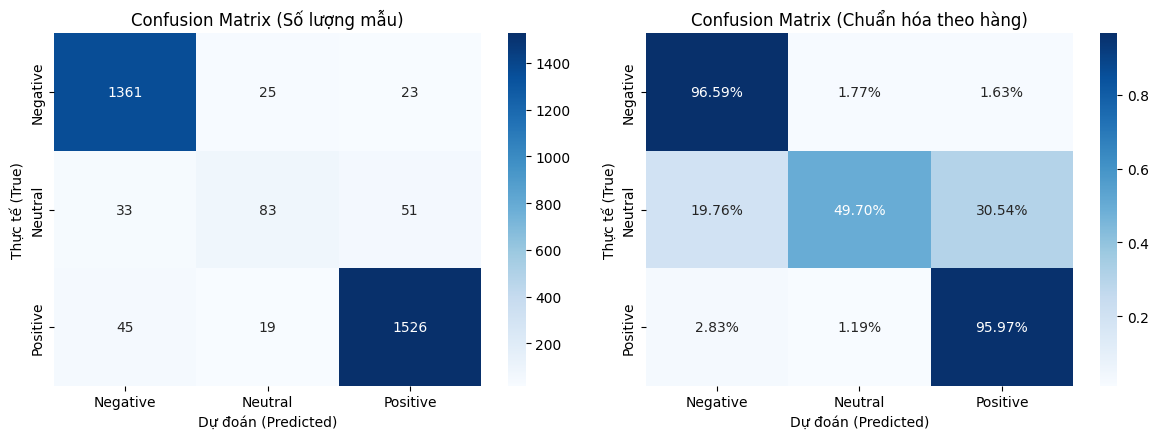

Đã lưu ảnh tại results/figures/phobert_confusion_matrix.png


In [ ]:
cm = confusion_matrix(test_df["label"], test_df["pred"])
cm_norm = cm.astype("float") / cm.sum(axis=1, keepdims=True)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=LABEL_NAMES, yticklabels=LABEL_NAMES, ax=axes[0])
axes[0].set_title("Confusion Matrix (Số lượng mẫu)")
axes[0].set_xlabel("Dự đoán (Predicted)")
axes[0].set_ylabel("Thực tế (True)")

sns.heatmap(cm_norm, annot=True, fmt=".2%", cmap="Blues", xticklabels=LABEL_NAMES, yticklabels=LABEL_NAMES, ax=axes[1])
axes[1].set_title("Confusion Matrix (Chuẩn hóa theo hàng)")
axes[1].set_xlabel("Dự đoán (Predicted)")
axes[1].set_ylabel("Thực tế (True)")

plt.tight_layout()
plt.savefig("results/figures/phobert_confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()
print("Đã lưu ảnh tại results/figures/phobert_confusion_matrix.png")

In [ ]:
errors_df = test_df[test_df["label"] != test_df["pred"]].copy()
errors_df["true_name"] = errors_df["label"].map(dict(enumerate(LABEL_NAMES)))
errors_df["pred_name"] = errors_df["pred"].map(dict(enumerate(LABEL_NAMES)))

# Sắp xếp các câu model tự tin nhất nhưng đoán sai để dễ phân tích lỗi
top_15_errors = errors_df.sort_values(by="confidence", ascending=False).head(15)

display(top_15_errors[["text", "true_name", "pred_name", "confidence"]])
top_15_errors[["text", "true_name", "pred_name", "confidence"]].to_csv(
    "../results/phobert_top15_errors.csv", index=False, encoding="utf-8-sig"
)
print("Đã xuất 15 ví dụ đoán sai tại results/phobert_top15_errors.csv")

,text,true_name,pred_name,confidence
2290,giảng viên thực hành nhiều bài thực hành trực ...,Negative,Positive,0.9917
2470,"dạy liên hệ thực tế , giảng dễ hiểu .",Negative,Positive,0.9916
971,giáo viên truyền đạt kinh nghiệm thực tế nhiều .,Neutral,Positive,0.9915
121,"ví dụ phù hợp với nội dung kiến thức , hướng d...",Neutral,Positive,0.9913
1085,sự tận tình .,Neutral,Positive,0.9913
1527,"nghiêm khắc trong khi dạy , kiến thức chuyên n...",Negative,Positive,0.9911
931,nói dễ nghe .,Neutral,Positive,0.9908
362,cô cho em 10 điểm thực hành colonlove .,Neutral,Positive,0.9907
2744,giảng dạy thực tế .,Neutral,Positive,0.9907
436,làm bài giảng sinh động .,Negative,Positive,0.9905


Đã xuất 15 ví dụ đoán sai tại results/phobert_top15_errors.csv


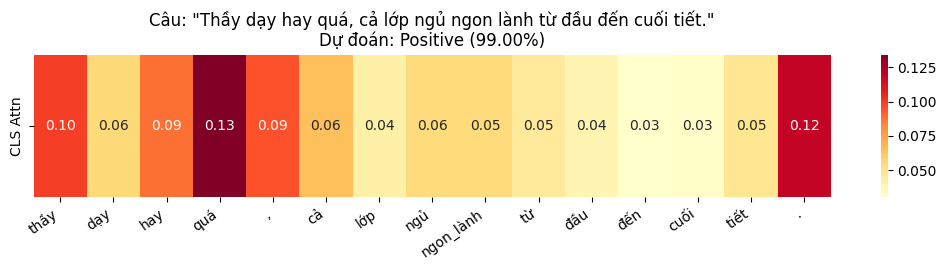

Đã lưu biểu đồ Attention tại: results/figures/attention_sarcasm.png


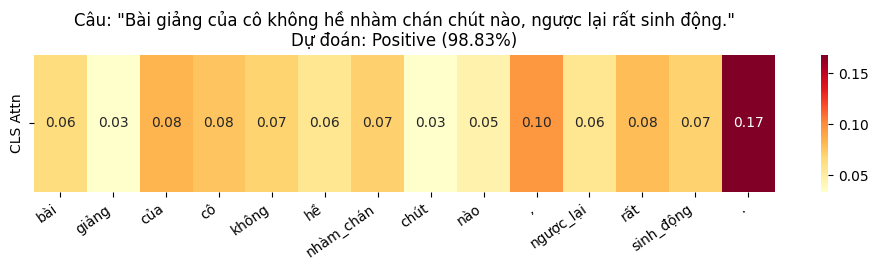

Đã lưu biểu đồ Attention tại: results/figures/attention_double_neg.png


In [ ]:
def visualize_attention(sentence: str, save_name: str = "attention_example.png"):
    clean_s = preprocess_pipeline(sentence, use_segment=True, normalize_noise=True)
    enc = tokenizer(clean_s, return_tensors="pt", truncation=True, max_length=128).to(DEVICE)

    with torch.no_grad():
        logits, attentions = model(
            input_ids=enc["input_ids"],
            attention_mask=enc["attention_mask"],
            output_attentions=True,
        )

    probs = torch.softmax(logits, dim=-1).cpu().numpy()[0]
    pred_label = LABEL_NAMES[int(np.argmax(probs))]

    # Lấy trung bình trọng số Attention của 12 heads ở tầng cuối cùng (layer -1)
    # Lấy hàng 0 (token <s> / CLS chú ý đến các token còn lại trong câu)
    last_layer_attn = attentions[-1][0].mean(dim=0).cpu().numpy()  # [seq_len, seq_len]
    cls_attn = last_layer_attn[0]

    tokens = tokenizer.convert_ids_to_tokens(enc["input_ids"][0])
    # Bỏ token <s> ở đầu và </s> ở cuối cho biểu đồ dễ nhìn
    tokens = tokens[1:-1]
    scores = cls_attn[1:-1]
    scores = scores / (scores.sum() + 1e-9)

    plt.figure(figsize=(max(8, len(tokens) * 0.7), 2.8))
    sns.heatmap(
        [scores],
        annot=True,
        fmt=".2f",
        cmap="YlOrRd",
        xticklabels=tokens,
        yticklabels=["CLS Attn"],
        cbar=True,
    )
    plt.title(f"Câu: \"{sentence}\"\nDự đoán: {pred_label} ({probs.max():.2%})")
    plt.xticks(rotation=35, ha="right")
    plt.tight_layout()
    save_path = os.path.join("results/figures", save_name)
    plt.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.show()
    print(f"Đã lưu biểu đồ Attention tại: {save_path}")

# Ví dụ chạy trực quan hóa trên 2 câu (1 câu mỉa mai, 1 câu phủ định kép)
visualize_attention(
    "Thầy dạy hay quá, cả lớp ngủ ngon lành từ đầu đến cuối tiết.",
    save_name="attention_sarcasm.png",
)
visualize_attention(
    "Bài giảng của cô không hề nhàm chán chút nào, ngược lại rất sinh động.",
    save_name="attention_double_neg.png",
)

In [ ]:
!cp -r results /content/drive/MyDrive/PhoBERT_UIT_VSFC/